In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path(r"C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL")

RUTA_LIMPIA = BASE_DIR / "02_datos_limpios" / "base_poder_judicial_limpia_v1.xlsx"
CARPETA_GRAFICOS = BASE_DIR / "04_graficos_resultados"
RUTA_CRUCES = BASE_DIR / "02_datos_limpios" / "cruces_indicadores_v1.xlsx"

CARPETA_GRAFICOS.mkdir(exist_ok=True)

df = pd.read_excel(RUTA_LIMPIA)

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
df.head()

Filas: 9695
Columnas: 64


,Fecha Intervención,Sexo denunciante,Edad denunciante,Relación denunciante/denunciada,Capacidades Diferentes denunciante,Pertenencia a Pueblos Originarios denunciante,Violencia Física,Violencia Psicológica,Violencia Económica,Violencia Sexual,...,Año,Mes,Edad denunciante limpia,Edad denunciada limpia,Violencia Física constatada,Violencia Psicológica constatada,Violencia Económica constatada,Violencia Sexual constatada,Violencia Restricción Participación Social constatada,Violencia Ambiental constatada
0,2022-03-21,F,26,7.0,2.0,2.0,0,3,0,0,...,2022,3,26.0,34.0,0,1,0,0,0,1
1,2022-04-01,F,11,5.0,1.0,2.0,0,0,0,1,...,2022,4,11.0,31.0,0,0,0,1,0,0
2,2022-04-29,F,23,2.0,2.0,2.0,3,2,0,0,...,2022,4,23.0,32.0,1,1,0,0,0,1
3,2022-04-07,F,21,1.0,1.0,2.0,2,3,3,0,...,2022,4,21.0,24.0,1,1,1,0,1,1
4,2022-01-04,F,27,1.0,2.0,2.0,2,3,2,0,...,2022,1,27.0,33.0,1,1,1,0,1,1


In [2]:
def guardar_grafico(nombre_archivo):
    ruta = CARPETA_GRAFICOS / nombre_archivo
    plt.tight_layout()
    plt.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()
    print("Gráfico guardado en:", ruta)

In [3]:
variables_violencia = [
    "Violencia Física",
    "Violencia Psicológica",
    "Violencia Económica",
    "Violencia Sexual",
    "Violencia Restricción Participación Social",
    "Violencia Ambiental"
]

medidas_judiciales = [
    "Abstención de publicación en Redes Sociales",
    "Alojamiento temporario de la víctima",
    "Custodia policial",
    "Desestimación de denuncia",
    "Exclusión del agresor",
    "Fijación de cuota alimentaria provisoria",
    "Fijación de régimen de visitas",
    "Guarda de menores/incapaces",
    "Guarda de menores/incapaces víctimas",
    "Levantamiento de la medida judicial",
    "Oficio de protección policial",
    "Orden para retirar enseres personales",
    "Otras Medidas",
    "Prohibición de acercamiento o comunicación del agresor",
    "Recursos de Revocatoria",
    "Reintegro al hogar a las víctimas",
    "Restitución de alimentos",
    "Restitución de bienes",
    "Retiro de la víctima",
    "Secuestro de arma",
    "Tratamientos de rehabilitación"
]

for col in variables_violencia:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

for col in medidas_judiciales:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

In [4]:
df["Cantidad tipos violencia"] = (df[variables_violencia] > 0).sum(axis=1)

df["Gravedad máxima registrada"] = df[variables_violencia].max(axis=1)

df["Suma niveles violencia"] = df[variables_violencia].sum(axis=1)

df["Cantidad medidas judiciales"] = df[medidas_judiciales].sum(axis=1)

df[[
    "Cantidad tipos violencia",
    "Gravedad máxima registrada",
    "Suma niveles violencia",
    "Cantidad medidas judiciales"
]].describe()

,Cantidad tipos violencia,Gravedad máxima registrada,Suma niveles violencia,Cantidad medidas judiciales
count,9695.000000,9695.000000,9695.000000,9695.000000
mean,1.771532,1.535018,3.553997,1.636204
std,1.455301,1.071599,3.565467,1.339513
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.000000,1.000000
50%,2.000000,2.000000,3.000000,1.000000
75%,3.000000,2.000000,6.000000,2.000000
max,6.000000,4.000000,24.000000,9.000000


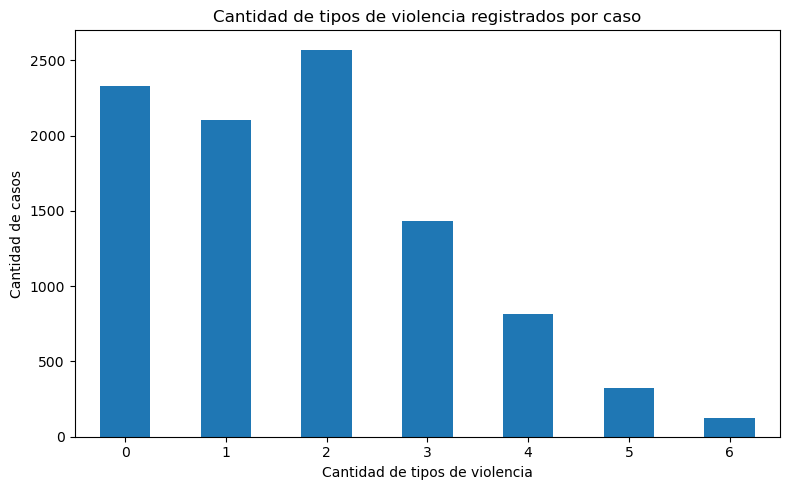

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\18_cantidad_tipos_violencia_por_caso.png


Cantidad tipos violencia
0    2326
1    2102
2    2570
3    1432
4     815
5     323
6     127
Name: count, dtype: int64

In [5]:
multiples_violencias = df["Cantidad tipos violencia"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
multiples_violencias.plot(kind="bar")
plt.title("Cantidad de tipos de violencia registrados por caso")
plt.xlabel("Cantidad de tipos de violencia")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=0)

guardar_grafico("18_cantidad_tipos_violencia_por_caso.png")

multiples_violencias

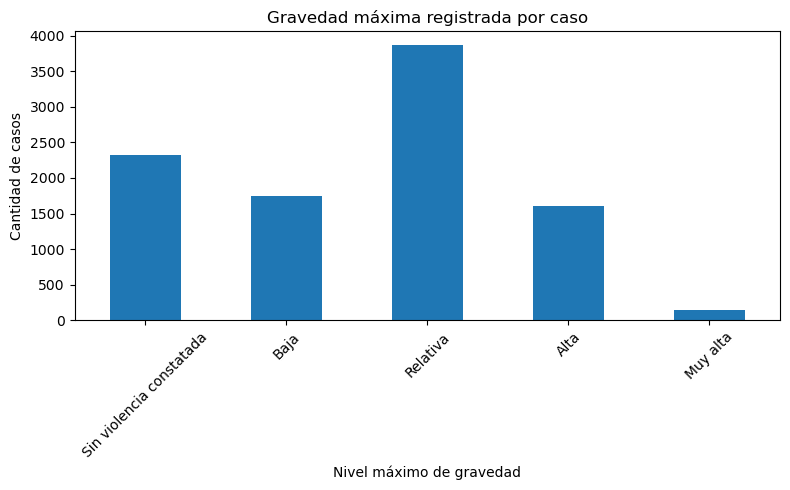

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\19_gravedad_maxima_por_caso.png


Gravedad máxima registrada
Sin violencia constatada    2326
Baja                        1749
Relativa                    3868
Alta                        1611
Muy alta                     141
Name: count, dtype: int64

In [6]:
mapa_gravedad = {
    0: "Sin violencia constatada",
    1: "Baja",
    2: "Relativa",
    3: "Alta",
    4: "Muy alta"
}

gravedad_maxima = (
    df["Gravedad máxima registrada"]
    .map(mapa_gravedad)
    .value_counts()
    .reindex(["Sin violencia constatada", "Baja", "Relativa", "Alta", "Muy alta"])
)

plt.figure(figsize=(8, 5))
gravedad_maxima.plot(kind="bar")
plt.title("Gravedad máxima registrada por caso")
plt.xlabel("Nivel máximo de gravedad")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=45)

guardar_grafico("19_gravedad_maxima_por_caso.png")

gravedad_maxima

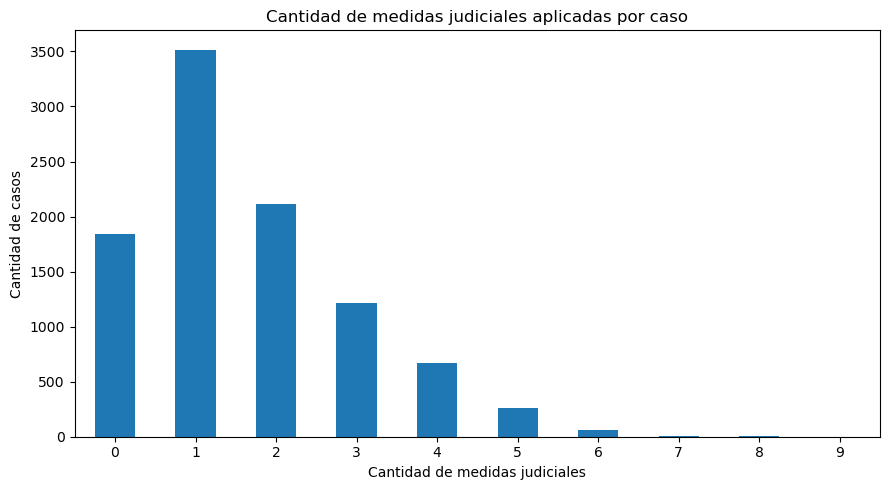

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\20_cantidad_medidas_judiciales_por_caso.png


Cantidad medidas judiciales
0    1845
1    3516
2    2112
3    1214
4     666
5     263
6      60
7      11
8       7
9       1
Name: count, dtype: int64

In [7]:
cantidad_medidas = df["Cantidad medidas judiciales"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
cantidad_medidas.plot(kind="bar")
plt.title("Cantidad de medidas judiciales aplicadas por caso")
plt.xlabel("Cantidad de medidas judiciales")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=0)

guardar_grafico("20_cantidad_medidas_judiciales_por_caso.png")

cantidad_medidas

In [8]:
tabla_gravedad_medidas = (
    df.groupby("Gravedad máxima registrada")["Cantidad medidas judiciales"]
    .agg(["count", "mean", "median", "max"])
    .reset_index()
)

tabla_gravedad_medidas["Gravedad"] = tabla_gravedad_medidas["Gravedad máxima registrada"].map(mapa_gravedad)

tabla_gravedad_medidas = tabla_gravedad_medidas[[
    "Gravedad",
    "count",
    "mean",
    "median",
    "max"
]]

tabla_gravedad_medidas.columns = [
    "Gravedad máxima",
    "Cantidad de casos",
    "Promedio de medidas",
    "Mediana de medidas",
    "Máximo de medidas"
]

tabla_gravedad_medidas

,Gravedad máxima,Cantidad de casos,Promedio de medidas,Mediana de medidas,Máximo de medidas
0,Sin violencia constatada,2326,0.805675,1.0,5
1,Baja,1749,1.295597,1.0,8
2,Relativa,3868,1.973371,2.0,9
3,Alta,1611,2.377405,2.0,8
4,Muy alta,141,1.843972,2.0,5


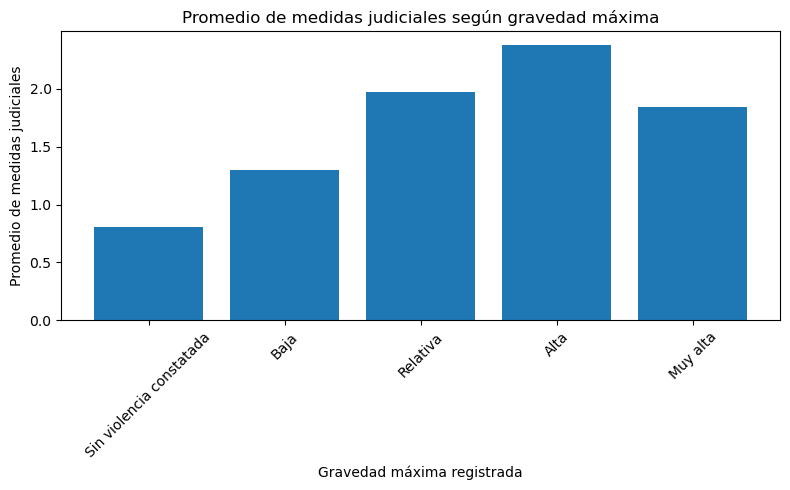

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\21_promedio_medidas_segun_gravedad.png


In [9]:
plt.figure(figsize=(8, 5))
plt.bar(
    tabla_gravedad_medidas["Gravedad máxima"],
    tabla_gravedad_medidas["Promedio de medidas"]
)

plt.title("Promedio de medidas judiciales según gravedad máxima")
plt.xlabel("Gravedad máxima registrada")
plt.ylabel("Promedio de medidas judiciales")
plt.xticks(rotation=45)

guardar_grafico("21_promedio_medidas_segun_gravedad.png")

In [10]:
tabla_tipos_medidas = (
    df.groupby("Cantidad tipos violencia")["Cantidad medidas judiciales"]
    .agg(["count", "mean", "median", "max"])
    .reset_index()
)

tabla_tipos_medidas.columns = [
    "Cantidad de tipos de violencia",
    "Cantidad de casos",
    "Promedio de medidas",
    "Mediana de medidas",
    "Máximo de medidas"
]

tabla_tipos_medidas

,Cantidad de tipos de violencia,Cantidad de casos,Promedio de medidas,Mediana de medidas,Máximo de medidas
0,0,2326,0.805675,1.0,5
1,1,2102,1.519029,1.0,8
2,2,2570,1.861868,2.0,9
3,3,1432,2.202514,2.0,8
4,4,815,2.283436,2.0,7
5,5,323,2.250774,2.0,7
6,6,127,2.118110,2.0,7


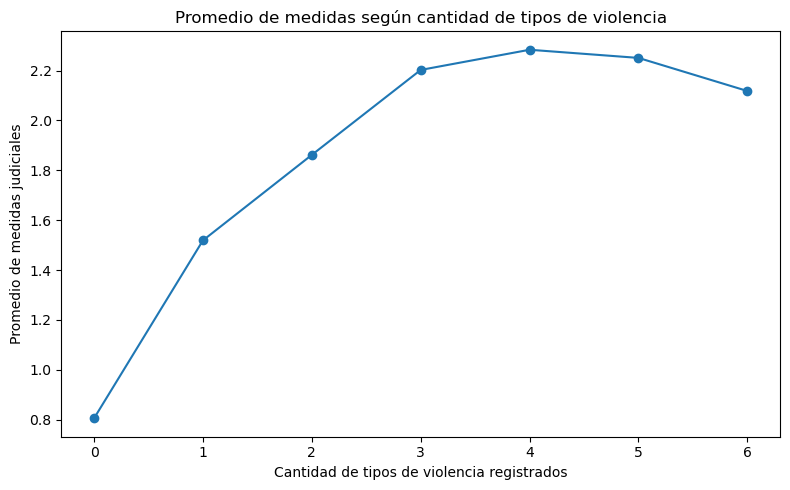

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\22_promedio_medidas_segun_tipos_violencia.png


In [11]:
plt.figure(figsize=(8, 5))
plt.plot(
    tabla_tipos_medidas["Cantidad de tipos de violencia"],
    tabla_tipos_medidas["Promedio de medidas"],
    marker="o"
)

plt.title("Promedio de medidas según cantidad de tipos de violencia")
plt.xlabel("Cantidad de tipos de violencia registrados")
plt.ylabel("Promedio de medidas judiciales")
plt.xticks(tabla_tipos_medidas["Cantidad de tipos de violencia"])

guardar_grafico("22_promedio_medidas_segun_tipos_violencia.png")

In [12]:
mapa_relacion = {
    1: "Unión convivencial",
    2: "Cónyuge",
    3: "Filial",
    4: "Fraternal",
    5: "Otros",
    6: "Novios",
    7: "Ex pareja",
    8: "Otros parientes"
}

df["Relación categorizada"] = df["Relación denunciante/denunciada"].map(mapa_relacion)

violencia_por_relacion = (
    df.groupby("Relación categorizada")[variables_violencia]
    .apply(lambda x: (x > 0).sum())
)

violencia_por_relacion

,Violencia Física,Violencia Psicológica,Violencia Económica,Violencia Sexual,Violencia Restricción Participación Social,Violencia Ambiental
Relación categorizada,,,,,,
Cónyuge,298,594,231,75,179,215
Ex pareja,1419,2981,909,232,823,996
Filial,337,779,251,16,71,358
Fraternal,115,269,76,6,28,127
Novios,154,241,22,8,58,74
Otros,116,275,63,40,30,122
Otros parientes,112,333,32,77,56,93
Unión convivencial,841,1429,447,136,381,519


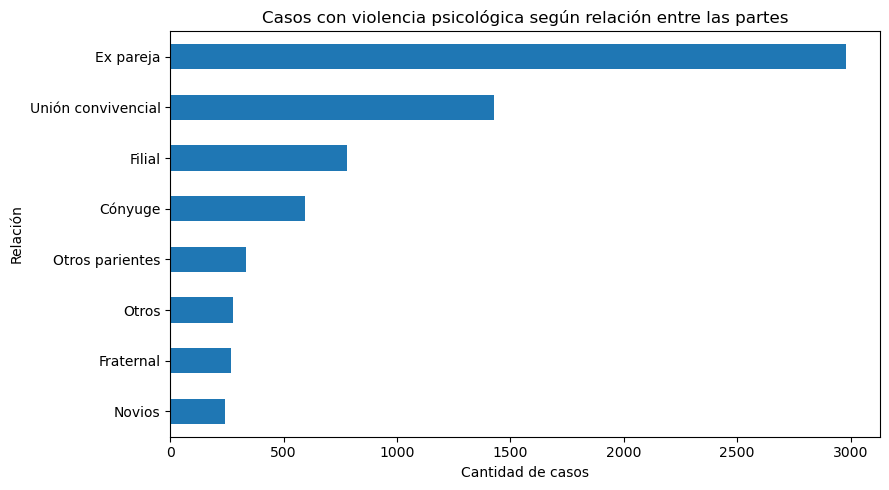

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\23_violencia_psicologica_por_relacion.png


Relación categorizada
Ex pareja             2981
Unión convivencial    1429
Filial                 779
Cónyuge                594
Otros parientes        333
Otros                  275
Fraternal              269
Novios                 241
Name: count, dtype: int64

In [13]:
violencia_psicologica_relacion = (
    df[df["Violencia Psicológica"] > 0]["Relación categorizada"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))
violencia_psicologica_relacion.plot(kind="barh")
plt.title("Casos con violencia psicológica según relación entre las partes")
plt.xlabel("Cantidad de casos")
plt.ylabel("Relación")

guardar_grafico("23_violencia_psicologica_por_relacion.png")

violencia_psicologica_relacion.sort_values(ascending=False)

In [14]:
medida_prohibicion = "Prohibición de acercamiento o comunicación del agresor"

tabla_fisica_prohibicion = pd.crosstab(
    df["Violencia Física"] > 0,
    df[medida_prohibicion] > 0,
    margins=True
)

tabla_fisica_prohibicion.index = ["Sin violencia física", "Con violencia física", "Total"]
tabla_fisica_prohibicion.columns = ["Sin prohibición", "Con prohibición", "Total"]

tabla_fisica_prohibicion

,Sin prohibición,Con prohibición,Total
Sin violencia física,3563,2704,6267
Con violencia física,777,2651,3428
Total,4340,5355,9695


In [15]:
tabla_fisica_prohibicion_pct = pd.crosstab(
    df["Violencia Física"] > 0,
    df[medida_prohibicion] > 0,
    normalize="index"
) * 100

tabla_fisica_prohibicion_pct.index = ["Sin violencia física", "Con violencia física"]
tabla_fisica_prohibicion_pct.columns = ["Sin prohibición", "Con prohibición"]

tabla_fisica_prohibicion_pct.round(2)

,Sin prohibición,Con prohibición
Sin violencia física,56.85,43.15
Con violencia física,22.67,77.33


In [16]:
medida_tratamiento = "Tratamientos de rehabilitación"

tabla_psico_tratamiento = pd.crosstab(
    df["Violencia Psicológica"] > 0,
    df[medida_tratamiento] > 0,
    margins=True
)

tabla_psico_tratamiento.index = ["Sin violencia psicológica", "Con violencia psicológica", "Total"]
tabla_psico_tratamiento.columns = ["Sin tratamiento", "Con tratamiento", "Total"]

tabla_psico_tratamiento

,Sin tratamiento,Con tratamiento,Total
Sin violencia psicológica,2547,191,2738
Con violencia psicológica,4756,2201,6957
Total,7303,2392,9695


In [17]:
tabla_psico_tratamiento_pct = pd.crosstab(
    df["Violencia Psicológica"] > 0,
    df[medida_tratamiento] > 0,
    normalize="index"
) * 100

tabla_psico_tratamiento_pct.index = ["Sin violencia psicológica", "Con violencia psicológica"]
tabla_psico_tratamiento_pct.columns = ["Sin tratamiento", "Con tratamiento"]

tabla_psico_tratamiento_pct.round(2)

,Sin tratamiento,Con tratamiento
Sin violencia psicológica,93.02,6.98
Con violencia psicológica,68.36,31.64


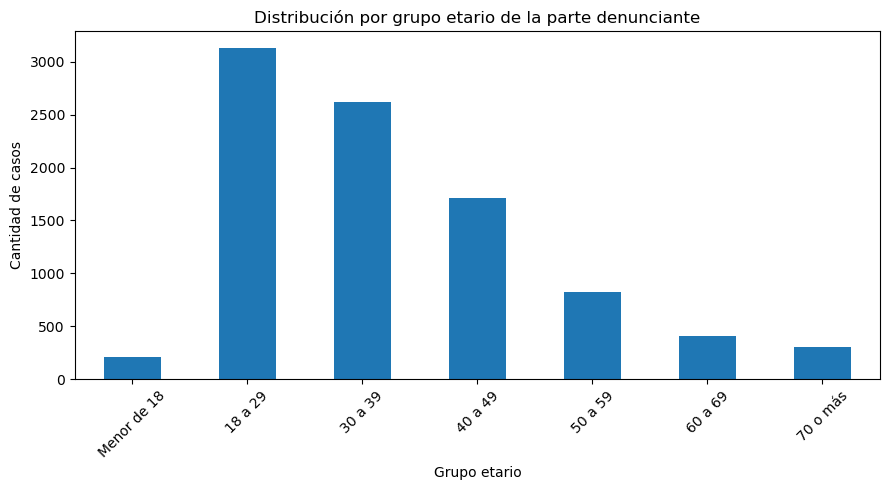

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\24_grupo_etario_denunciante.png


Grupo etario denunciante
Menor de 18     210
18 a 29        3133
30 a 39        2620
40 a 49        1711
50 a 59         821
60 a 69         410
70 o más        300
Name: count, dtype: int64

In [18]:
bins_edad = [0, 17, 29, 39, 49, 59, 69, 100]
labels_edad = [
    "Menor de 18",
    "18 a 29",
    "30 a 39",
    "40 a 49",
    "50 a 59",
    "60 a 69",
    "70 o más"
]

df["Grupo etario denunciante"] = pd.cut(
    df["Edad denunciante limpia"],
    bins=bins_edad,
    labels=labels_edad,
    include_lowest=True
)

grupo_etario_denunciante = (
    df["Grupo etario denunciante"]
    .value_counts()
    .reindex(labels_edad)
)

plt.figure(figsize=(9, 5))
grupo_etario_denunciante.plot(kind="bar")
plt.title("Distribución por grupo etario de la parte denunciante")
plt.xlabel("Grupo etario")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=45)

guardar_grafico("24_grupo_etario_denunciante.png")

grupo_etario_denunciante

In [19]:
violencia_por_grupo_etario = (
    df.groupby("Grupo etario denunciante", observed=False)[variables_violencia]
    .apply(lambda x: (x > 0).sum())
)

violencia_por_grupo_etario

,Violencia Física,Violencia Psicológica,Violencia Económica,Violencia Sexual,Violencia Restricción Participación Social,Violencia Ambiental
Grupo etario denunciante,,,,,,
Menor de 18,94,118,19,64,37,33
18 a 29,1258,2205,576,184,592,764
30 a 39,955,1922,592,176,476,684
40 a 49,564,1266,404,107,292,466
50 a 59,217,581,182,38,110,236
60 a 69,124,298,97,8,45,143
70 o más,88,239,116,3,37,117


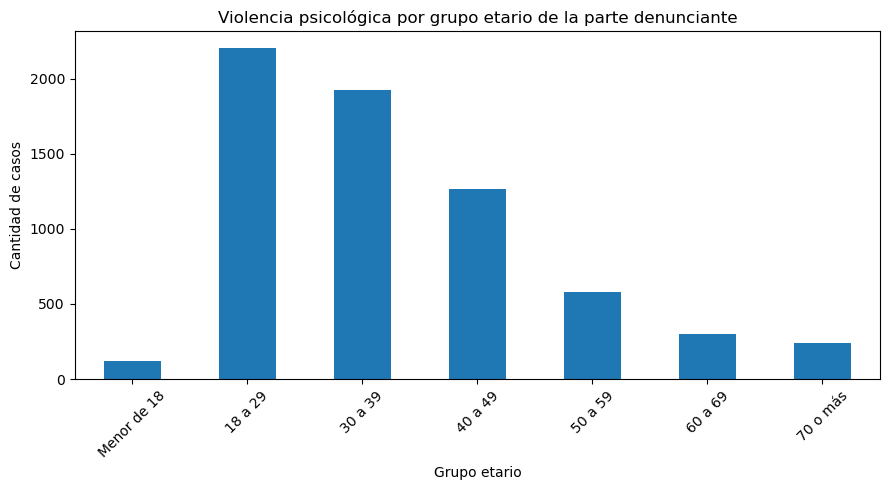

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\25_violencia_psicologica_por_grupo_etario.png


Grupo etario denunciante
Menor de 18     118
18 a 29        2205
30 a 39        1922
40 a 49        1266
50 a 59         581
60 a 69         298
70 o más        239
Name: Violencia Psicológica, dtype: int64

In [20]:
psicologica_grupo_etario = violencia_por_grupo_etario["Violencia Psicológica"]

plt.figure(figsize=(9, 5))
psicologica_grupo_etario.plot(kind="bar")
plt.title("Violencia psicológica por grupo etario de la parte denunciante")
plt.xlabel("Grupo etario")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=45)

guardar_grafico("25_violencia_psicologica_por_grupo_etario.png")

psicologica_grupo_etario

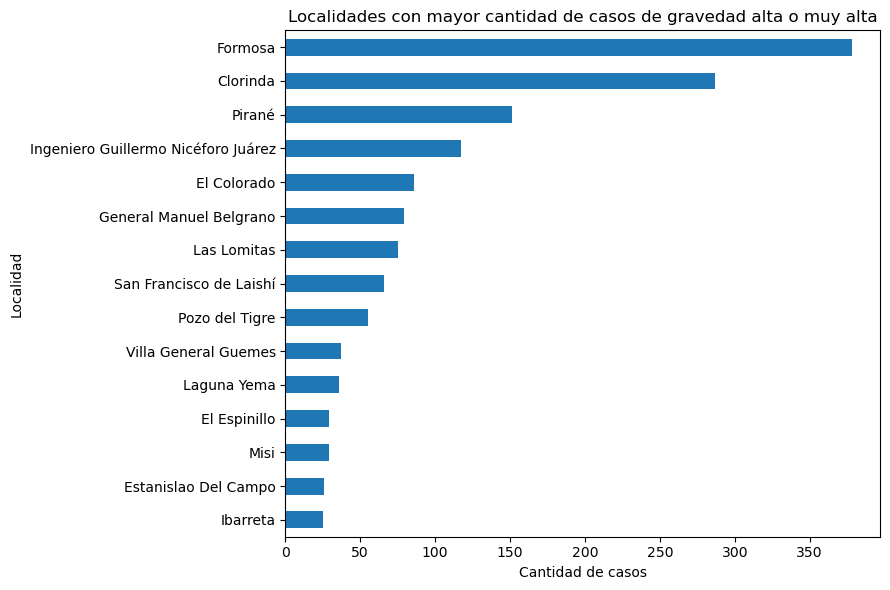

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\26_localidades_casos_graves.png


Localidad Hecho
Formosa                                378
Clorinda                               287
Pirané                                 151
Ingeniero Guillermo Nicéforo Juárez    117
El Colorado                             86
General Manuel Belgrano                 79
Las Lomitas                             75
San Francisco de Laishí                 66
Pozo del Tigre                          55
Villa General Guemes                    37
Laguna Yema                             36
Misi                                    29
El Espinillo                            29
Estanislao Del Campo                    26
Ibarreta                                25
dtype: int64

In [21]:
casos_graves_localidad = (
    df[df["Gravedad máxima registrada"] >= 3]
    .groupby("Localidad Hecho")
    .size()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(9, 6))
casos_graves_localidad.sort_values(ascending=True).plot(kind="barh")
plt.title("Localidades con mayor cantidad de casos de gravedad alta o muy alta")
plt.xlabel("Cantidad de casos")
plt.ylabel("Localidad")

guardar_grafico("26_localidades_casos_graves.png")

casos_graves_localidad

In [22]:
RUTA_BASE_ENRIQUECIDA = BASE_DIR / "02_datos_limpios" / "base_poder_judicial_enriquecida_v1.xlsx"

df.to_excel(RUTA_BASE_ENRIQUECIDA, index=False)

with pd.ExcelWriter(RUTA_CRUCES) as writer:
    multiples_violencias.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Tipos violencia por caso")
    gravedad_maxima.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Gravedad maxima")
    cantidad_medidas.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Medidas por caso")
    tabla_gravedad_medidas.to_excel(writer, sheet_name="Gravedad y medidas", index=False)
    tabla_tipos_medidas.to_excel(writer, sheet_name="Tipos y medidas", index=False)
    violencia_por_relacion.to_excel(writer, sheet_name="Violencia por relacion")
    tabla_fisica_prohibicion.to_excel(writer, sheet_name="Fisica prohibicion")
    tabla_fisica_prohibicion_pct.round(2).to_excel(writer, sheet_name="Fisica prohibicion pct")
    tabla_psico_tratamiento.to_excel(writer, sheet_name="Psico tratamiento")
    tabla_psico_tratamiento_pct.round(2).to_excel(writer, sheet_name="Psico tratamiento pct")
    grupo_etario_denunciante.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Grupo etario")
    violencia_por_grupo_etario.to_excel(writer, sheet_name="Violencia grupo etario")
    casos_graves_localidad.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Localidades graves")

print("Base enriquecida guardada en:")
print(RUTA_BASE_ENRIQUECIDA)

print("Tablas de cruces guardadas en:")
print(RUTA_CRUCES)

Base enriquecida guardada en:
C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\02_datos_limpios\base_poder_judicial_enriquecida_v1.xlsx
Tablas de cruces guardadas en:
C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\02_datos_limpios\cruces_indicadores_v1.xlsx
